**Instalar dependencias**

In [1]:

%pip install -q kagglehub tensorflow scikit-learn pandas numpy matplotlib seaborn pillow


**Importar librerías y comprobar GPU**

In [2]:

import os
import json
import hashlib
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image
from collections import Counter, defaultdict
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU disponibles:", tf.config.list_physical_devices("GPU"))

if not tf.config.list_physical_devices("GPU"):
    print("ADVERTENCIA: No se detectó GPU.")


TensorFlow: 2.21.0
GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


**Descargar el dataset**

In [3]:

import kagglehub

ruta_dataset = Path(
    kagglehub.dataset_download(
        "muhriddinmuxiddinov/fruits-and-vegetables-dataset"
    )
)

print("Dataset descargado en:")
print(ruta_dataset)

print("\nContenido:")
for elemento in sorted(ruta_dataset.iterdir()):
    print(
        "CARPETA" if elemento.is_dir() else "ARCHIVO",
        elemento.name
    )


100%|██████████| 870M/870M [00:08<00:00, 107MB/s]

Extracting files...


Dataset descargado en:
/root/.cache/kagglehub/datasets/muhriddinmuxiddinov/fruits-and-vegetables-dataset/versions/2

Contenido:
CARPETA Fruits_Vegetables_Dataset(12000)


**Localizar las carpetas de frutas y verduras**

In [4]:

nombre_carpeta = "Fruits_Vegetables_Dataset(12000)"

carpeta_principal = ruta_dataset / nombre_carpeta

carpeta_frutas = carpeta_principal / "Fruits"
carpeta_verduras = carpeta_principal / "Vegetables"

assert carpeta_frutas.exists(), "No se encontró la carpeta Fruits"
assert carpeta_verduras.exists(), "No se encontró la carpeta Vegetables"

print("Frutas:", carpeta_frutas)
print("Verduras:", carpeta_verduras)

print("\nClases de frutas:")
for carpeta in sorted(carpeta_frutas.iterdir()):
    if carpeta.is_dir():
        print(carpeta.name)

print("\nClases de verduras:")
for carpeta in sorted(carpeta_verduras.iterdir()):
    if carpeta.is_dir():
        print(carpeta.name)


Frutas: /root/.cache/kagglehub/datasets/muhriddinmuxiddinov/fruits-and-vegetables-dataset/versions/2/Fruits_Vegetables_Dataset(12000)/Fruits
Verduras: /root/.cache/kagglehub/datasets/muhriddinmuxiddinov/fruits-and-vegetables-dataset/versions/2/Fruits_Vegetables_Dataset(12000)/Vegetables

Clases de frutas:
FreshApple
FreshBanana
FreshMango
FreshOrange
FreshStrawberry
RottenApple
RottenBanana
RottenMango
RottenOrange
RottenStrawberry

Clases de verduras:
FreshBellpepper
FreshCarrot
FreshCucumber
FreshPotato
FreshTomato
RottenBellpepper
RottenCarrot
RottenCucumber
RottenPotato
RottenTomato


**Inventario completo**

In [5]:

EXTENSIONES = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

registros = []

for categoria_principal in [carpeta_frutas, carpeta_verduras]:

    for carpeta_clase in sorted(categoria_principal.iterdir()):

        if not carpeta_clase.is_dir():
            continue

        for archivo in carpeta_clase.rglob("*"):

            if archivo.is_file() and archivo.suffix.lower() in EXTENSIONES:

                registros.append({
                    "filepath": str(archivo),
                    "label": carpeta_clase.name,
                    "tipo": categoria_principal.name
                })

df_original = pd.DataFrame(registros)

print("TOTAL DE IMÁGENES:", len(df_original))
print("\nDISTRIBUCIÓN POR CLASE:")
print(df_original["label"].value_counts().sort_index())

print("\nDISTRIBUCIÓN POR CATEGORÍA:")
print(df_original["tipo"].value_counts())


TOTAL DE IMÁGENES: 12000

DISTRIBUCIÓN POR CLASE:
label
FreshApple          612
FreshBanana         624
FreshBellpepper     611
FreshCarrot         620
FreshCucumber       608
FreshMango          605
FreshOrange         609
FreshPotato         615
FreshStrawberry     603
FreshTomato         604
RottenApple         588
RottenBanana        576
RottenBellpepper    591
RottenCarrot        580
RottenCucumber      593
RottenMango         593
RottenOrange        591
RottenPotato        585
RottenStrawberry    596
RottenTomato        596
Name: count, dtype: int64

DISTRIBUCIÓN POR CATEGORÍA:
tipo
Vegetables    6003
Fruits        5997
Name: count, dtype: int64


**Detectar imágenes dañadas**

In [6]:

imagenes_danadas = []

for ruta in df_original["filepath"]:
    try:
        with Image.open(ruta) as img:
            img.verify()
    except Exception as e:
        imagenes_danadas.append({
            "filepath": ruta,
            "error": str(e)
        })

print("Total de imágenes revisadas:", len(df_original))
print("Imágenes dañadas:", len(imagenes_danadas))

if imagenes_danadas:
    print("\nPrimeras imágenes dañadas:")
    print(pd.DataFrame(imagenes_danadas).head(10))
else:
    print("Todas las imágenes son válidas.")


Total de imágenes revisadas: 12000
Imágenes dañadas: 0
Todas las imágenes son válidas.


**Detectar imágenes duplicadas mediante SHA-256**

In [7]:

duplicados = defaultdict(list)

for ruta in df_original["filepath"]:
    sha256 = hashlib.sha256()

    with open(ruta, "rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            sha256.update(bloque)

    duplicados[sha256.hexdigest()].append(ruta)

grupos_duplicados = {
    hash_img: rutas
    for hash_img, rutas in duplicados.items()
    if len(rutas) > 1
}

total_archivos_duplicados = sum(
    len(rutas) for rutas in grupos_duplicados.values()
)

archivos_redundantes = sum(
    len(rutas) - 1 for rutas in grupos_duplicados.values()
)

print("Grupos de imágenes duplicadas:", len(grupos_duplicados))
print("Archivos involucrados:", total_archivos_duplicados)
print("Copias redundantes:", archivos_redundantes)
print("Imágenes con hash único:", len(df_original) - archivos_redundantes)


Grupos de imágenes duplicadas: 224
Archivos involucrados: 456
Copias redundantes: 232
Imágenes con hash único: 11768


**Identificar duplicados con etiquetas diferentes**

In [8]:

ruta_a_clase = dict(
    zip(df_original["filepath"], df_original["label"])
)

conflictos = []

for hash_img, rutas in grupos_duplicados.items():

    clases = sorted(set(ruta_a_clase[ruta] for ruta in rutas))

    if len(clases) > 1:
        conflictos.append({
            "hash": hash_img,
            "clases": clases,
            "archivos": rutas
        })

print("GRUPOS CON ETIQUETAS DIFERENTES:", len(conflictos))

for i, conflicto in enumerate(conflictos, start=1):
    print(f"\nCONFLICTO {i}")
    print("Clases:", conflicto["clases"])

    for ruta in conflicto["archivos"]:
        print("-", ruta_a_clase[ruta], "|", Path(ruta).name)


GRUPOS CON ETIQUETAS DIFERENTES: 2

CONFLICTO 1
Clases: ['FreshCarrot', 'RottenCarrot']
- FreshCarrot | freshCarrot (534).jpg
- RottenCarrot | rottenCarrot (31).jpg
- RottenCarrot | rottenCarrot (549).jpg

CONFLICTO 2
Clases: ['FreshCarrot', 'RottenCarrot']
- FreshCarrot | freshCarrot (536).jpg
- RottenCarrot | rottenCarrot (527).jpg


**Construir el dataset limpio y generar su manifiesto.**

In [9]:

# Identificar todos los archivos pertenecientes a conflictos
archivos_conflictivos = {
    ruta
    for conflicto in conflictos
    for ruta in conflicto["archivos"]
}

# Agrupar hashes por clase
grupos_por_hash = defaultdict(list)

for hash_img, rutas in duplicados.items():

    for ruta in rutas:
        if ruta not in archivos_conflictivos:
            grupos_por_hash[hash_img].append(ruta)

# Conservar una sola imagen por hash y etiqueta
registros_limpios = []

for hash_img, rutas in grupos_por_hash.items():

    ruta = sorted(rutas)[0]
    label = ruta_a_clase[ruta]

    tipo = (
        "Fruits"
        if label in [x.name for x in carpeta_frutas.iterdir() if x.is_dir()]
        else "Vegetables"
    )

    registros_limpios.append({
        "filepath": ruta,
        "label": label,
        "tipo": tipo,
        "sha256": hash_img
    })

df_limpio = pd.DataFrame(registros_limpios)

print("IMÁGENES ORIGINALES:", len(df_original))
print("ARCHIVOS CON ETIQUETAS CONFLICTIVAS:", len(archivos_conflictivos))
print("IMÁGENES LIMPIAS:", len(df_limpio))

print("\nDISTRIBUCIÓN POR CLASE:")
print(df_limpio["label"].value_counts().sort_index())

print("\nDUPLICADOS RESTANTES:", df_limpio["sha256"].duplicated().sum())
print("\nCLASES ENCONTRADAS:", df_limpio["label"].nunique())


IMÁGENES ORIGINALES: 12000
ARCHIVOS CON ETIQUETAS CONFLICTIVAS: 5
IMÁGENES LIMPIAS: 11766

DISTRIBUCIÓN POR CLASE:
label
FreshApple          606
FreshBanana         623
FreshBellpepper     600
FreshCarrot         608
FreshCucumber       591
FreshMango          605
FreshOrange         609
FreshPotato         610
FreshStrawberry     603
FreshTomato         602
RottenApple         586
RottenBanana        576
RottenBellpepper    547
RottenCarrot        506
RottenCucumber      576
RottenMango         593
RottenOrange        591
RottenPotato        564
RottenStrawberry    596
RottenTomato        574
Name: count, dtype: int64

DUPLICADOS RESTANTES: 0

CLASES ENCONTRADAS: 20


**Guardar el manifiesto del dataset limpio.**

In [10]:

# Crear carpeta de trabajo
CARPETA_TRABAJO = Path("/content/FruitVisionAI")

CARPETA_TRABAJO.mkdir(parents=True, exist_ok=True)

# Guardar manifiesto limpio
ruta_manifiesto = CARPETA_TRABAJO / "manifest_clean.csv"

df_limpio.to_csv(ruta_manifiesto, index=False)

# Guardar registro de archivos conflictivos excluidos
df_conflictos = pd.DataFrame([
    {
        "filepath": ruta,
        "label": ruta_a_clase[ruta]
    }
    for ruta in sorted(archivos_conflictivos)
])

ruta_conflictos = CARPETA_TRABAJO / "conflictos_excluidos.csv"

df_conflictos.to_csv(ruta_conflictos, index=False)

print("Manifiesto limpio:", ruta_manifiesto)
print("Conflictos excluidos:", ruta_conflictos)

print("\nArchivos guardados:")
for archivo in CARPETA_TRABAJO.iterdir():
    print(archivo.name, "-", archivo.stat().st_size, "bytes")


Manifiesto limpio: /content/FruitVisionAI/manifest_clean.csv
Conflictos excluidos: /content/FruitVisionAI/conflictos_excluidos.csv

Archivos guardados:
manifest_clean.csv - 3037578 bytes
conflictos_excluidos.csv - 938 bytes


**Dividir el dataset en entrenamiento, validación y prueba.**

In [11]:

df_train, df_temporal = train_test_split(
    df_limpio,
    test_size=0.30,
    random_state=SEED,
    stratify=df_limpio["label"]
)

df_val, df_test = train_test_split(
    df_temporal,
    test_size=0.50,
    random_state=SEED,
    stratify=df_temporal["label"]
)

print("DISTRIBUCIÓN DE LOS DATOS")
print("-------------------------")
print("Entrenamiento:", len(df_train))
print("Validación:", len(df_val))
print("Prueba:", len(df_test))
print("Total:", len(df_train) + len(df_val) + len(df_test))

print("\nPORCENTAJE:")
print("Entrenamiento:", round(len(df_train) / len(df_limpio) * 100, 2), "%")
print("Validación:", round(len(df_val) / len(df_limpio) * 100, 2), "%")
print("Prueba:", round(len(df_test) / len(df_limpio) * 100, 2), "%")


DISTRIBUCIÓN DE LOS DATOS
-------------------------
Entrenamiento: 8236
Validación: 1765
Prueba: 1765
Total: 11766

PORCENTAJE:
Entrenamiento: 70.0 %
Validación: 15.0 %
Prueba: 15.0 %


**Verificar que no existan imágenes duplicadas entre los tres conjuntos.**

In [12]:

hash_train = set(df_train["sha256"])
hash_val = set(df_val["sha256"])
hash_test = set(df_test["sha256"])

print("Duplicados entre entrenamiento y validación:",
      len(hash_train & hash_val))

print("Duplicados entre entrenamiento y prueba:",
      len(hash_train & hash_test))

print("Duplicados entre validación y prueba:",
      len(hash_val & hash_test))

assert len(hash_train & hash_val) == 0
assert len(hash_train & hash_test) == 0
assert len(hash_val & hash_test) == 0

print("\nVERIFICACIÓN CORRECTA: no existe fuga de datos por duplicados.")


Duplicados entre entrenamiento y validación: 0
Duplicados entre entrenamiento y prueba: 0
Duplicados entre validación y prueba: 0

VERIFICACIÓN CORRECTA: no existe fuga de datos por duplicados.


**Guardar las tres particiones en archivos CSV.**

In [13]:

ruta_train = CARPETA_TRABAJO / "train.csv"
ruta_val = CARPETA_TRABAJO / "validation.csv"
ruta_test = CARPETA_TRABAJO / "test.csv"

df_train.to_csv(ruta_train, index=False)
df_val.to_csv(ruta_val, index=False)
df_test.to_csv(ruta_test, index=False)

print("Particiones guardadas correctamente:\n")

for archivo in [ruta_train, ruta_val, ruta_test]:
    print(archivo.name, "-", archivo.stat().st_size, "bytes")


Particiones guardadas correctamente:

train.csv - 2126243 bytes
validation.csv - 455697 bytes
test.csv - 455692 bytes


**Definir las 20 clases y guardar su orden**.

El modelo utilizará índices numéricos para representar cada clase, y la aplicación deberá interpretar esos índices exactamente igual.

In [14]:

class_names = sorted(df_limpio["label"].unique().tolist())

class_to_index = {
    nombre: indice
    for indice, nombre in enumerate(class_names)
}

ruta_clases = CARPETA_TRABAJO / "class_names.json"

with open(ruta_clases, "w", encoding="utf-8") as archivo:
    json.dump(class_names, archivo, indent=4, ensure_ascii=False)

print("TOTAL DE CLASES:", len(class_names))
print("\nMAPEO DE CLASES:")

for nombre, indice in class_to_index.items():
    print(indice, "->", nombre)

print("\nArchivo guardado:", ruta_clases)


TOTAL DE CLASES: 20

MAPEO DE CLASES:
0 -> FreshApple
1 -> FreshBanana
2 -> FreshBellpepper
3 -> FreshCarrot
4 -> FreshCucumber
5 -> FreshMango
6 -> FreshOrange
7 -> FreshPotato
8 -> FreshStrawberry
9 -> FreshTomato
10 -> RottenApple
11 -> RottenBanana
12 -> RottenBellpepper
13 -> RottenCarrot
14 -> RottenCucumber
15 -> RottenMango
16 -> RottenOrange
17 -> RottenPotato
18 -> RottenStrawberry
19 -> RottenTomato

Archivo guardado: /content/FruitVisionAI/class_names.json


**Comprobar la distribución de las 20 clases en cada partición.**

In [15]:

distribucion = pd.DataFrame({
    "Entrenamiento": df_train["label"].value_counts(),
    "Validación": df_val["label"].value_counts(),
    "Prueba": df_test["label"].value_counts()
}).fillna(0).astype(int).sort_index()

print(distribucion)

print("\nClases en entrenamiento:", df_train["label"].nunique())
print("Clases en validación:", df_val["label"].nunique())
print("Clases en prueba:", df_test["label"].nunique())

assert (distribucion > 0).all().all()

print("\nCORRECTO: las 20 clases están presentes en las tres particiones.")


                  Entrenamiento  Validación  Prueba
label                                              
FreshApple                  424          91      91
FreshBanana                 436          94      93
FreshBellpepper             420          90      90
FreshCarrot                 426          91      91
FreshCucumber               414          88      89
FreshMango                  424          91      90
FreshOrange                 426          91      92
FreshPotato                 427          91      92
FreshStrawberry             422          91      90
FreshTomato                 421          90      91
RottenApple                 410          88      88
RottenBanana                403          86      87
RottenBellpepper            383          82      82
RottenCarrot                354          76      76
RottenCucumber              403          87      86
RottenMango                 415          89      89
RottenOrange                414          89      88
RottenPotato

**Visualizar ejemplos de las 20 clases.**

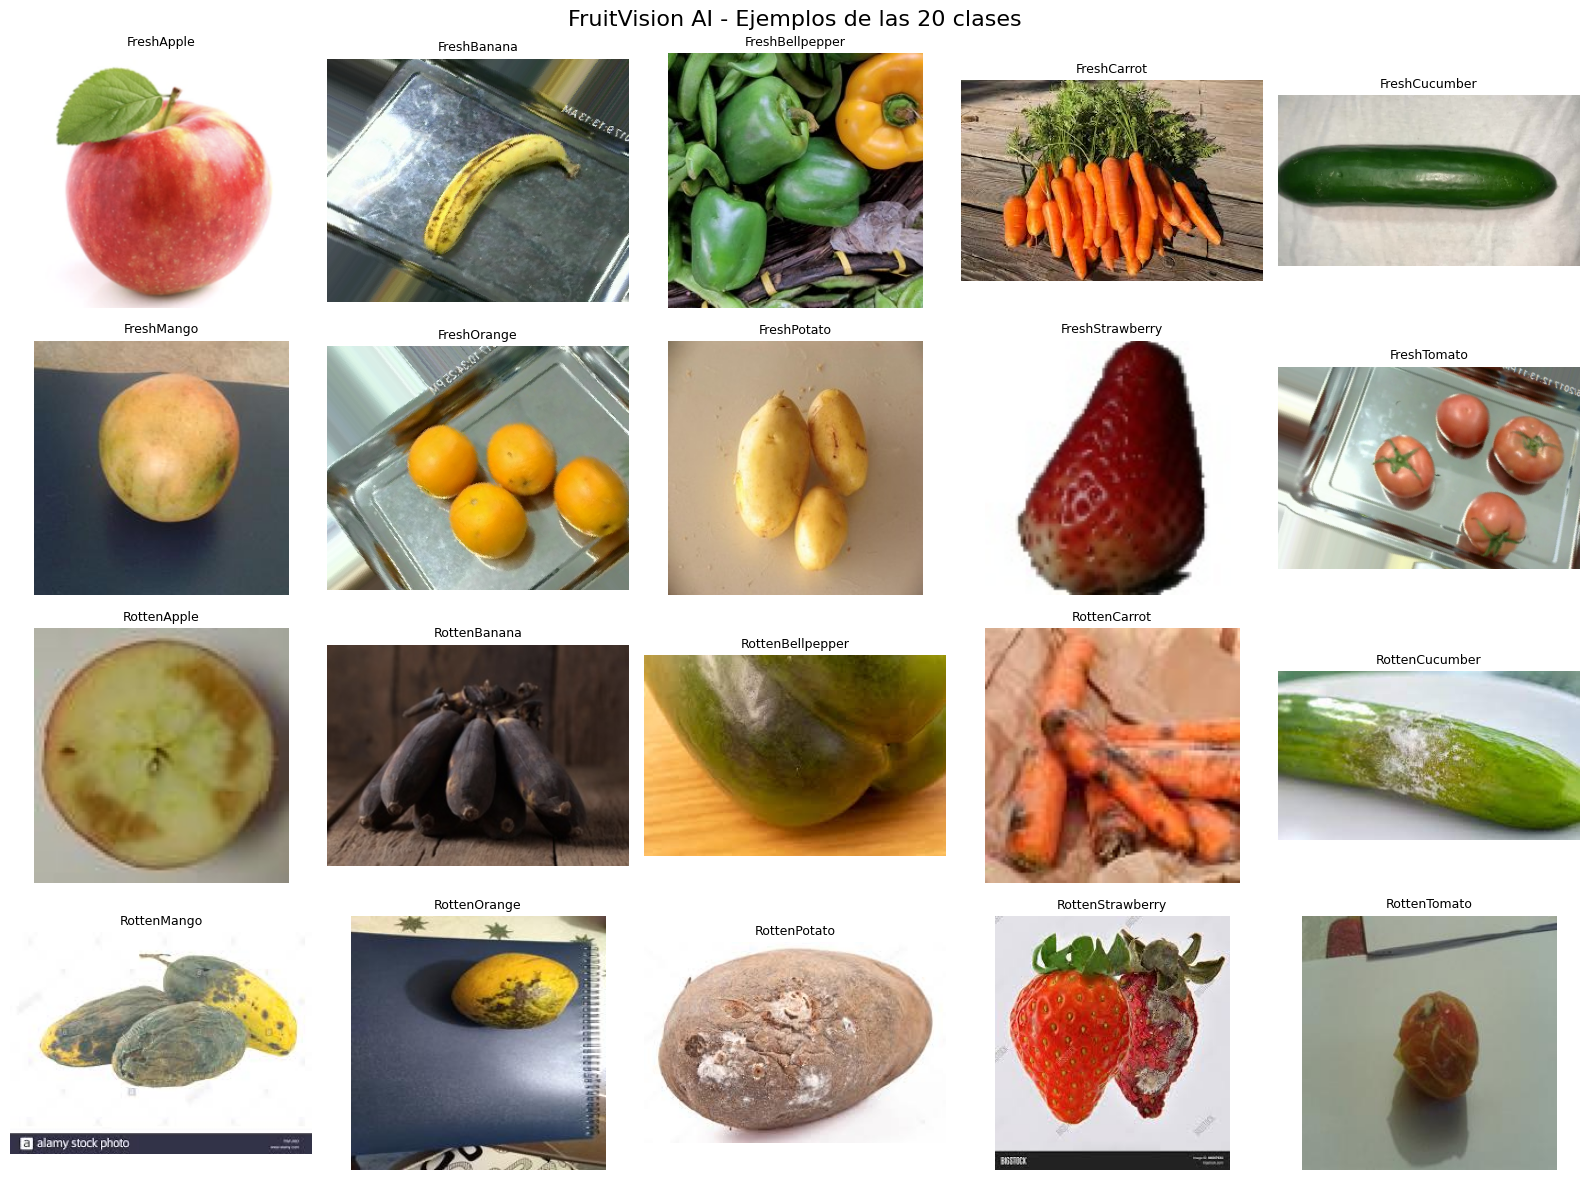

In [16]:

plt.figure(figsize=(16, 12))

for i, clase in enumerate(class_names):
    muestra = df_train[df_train["label"] == clase].sample(
        1, random_state=SEED
    ).iloc[0]

    imagen = Image.open(muestra["filepath"]).convert("RGB")

    plt.subplot(4, 5, i + 1)
    plt.imshow(imagen)
    plt.title(clase, fontsize=9)
    plt.axis("off")

plt.suptitle(
    "FruitVision AI - Ejemplos de las 20 clases",
    fontsize=16
)

plt.tight_layout()
plt.show()


**Configurar los parámetros del modelo EfficientNetB0**

In [17]:

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
NUM_CLASSES = len(class_names)

EPOCHS_INICIAL = 15
EPOCHS_FINE_TUNING = 15

print("Tamaño de imagen:", IMG_SIZE)
print("Tamaño del lote:", BATCH_SIZE)
print("Número de clases:", NUM_CLASSES)
print("Épocas iniciales:", EPOCHS_INICIAL)
print("Épocas de ajuste fino:", EPOCHS_FINE_TUNING)


Tamaño de imagen: (224, 224)
Tamaño del lote: 32
Número de clases: 20
Épocas iniciales: 15
Épocas de ajuste fino: 15


**Crear el cargador de imágenes para entrenamiento, validación y prueba.**

Esta celda leerá las rutas de los CSV, convertirá las imágenes a RGB y las redimensionará. No se aplicaran aumentos todavía.

In [18]:

AUTOTUNE = tf.data.AUTOTUNE

def cargar_imagen(ruta, etiqueta):
    imagen = tf.io.read_file(ruta)
    imagen = tf.io.decode_image(
        imagen,
        channels=3,
        expand_animations=False
    )
    imagen.set_shape([None, None, 3])
    imagen = tf.image.resize(imagen, IMG_SIZE)
    imagen = tf.cast(imagen, tf.float32)

    return imagen, etiqueta


def crear_dataset(dataframe, entrenamiento=False):
    rutas = dataframe["filepath"].values
    etiquetas = dataframe["label"].map(class_to_index).values

    dataset = tf.data.Dataset.from_tensor_slices((rutas, etiquetas))

    if entrenamiento:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        cargar_imagen,
        num_parallel_calls=AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)

    return dataset


train_ds = crear_dataset(df_train, entrenamiento=True)
val_ds = crear_dataset(df_val)
test_ds = crear_dataset(df_test)

print("Datasets creados correctamente.")
print("Lotes de entrenamiento:", tf.data.experimental.cardinality(train_ds).numpy())
print("Lotes de validación:", tf.data.experimental.cardinality(val_ds).numpy())
print("Lotes de prueba:", tf.data.experimental.cardinality(test_ds).numpy())


Datasets creados correctamente.
Lotes de entrenamiento: 258
Lotes de validación: 56
Lotes de prueba: 56


**Comprobar que las imágenes y etiquetas se cargan correctamente**

Forma del lote de imágenes: (32, 224, 224, 3)
Forma del lote de etiquetas: (32,)
Tipo de dato: <dtype: 'float32'>
Valor mínimo: 0.0
Valor máximo: 255.0


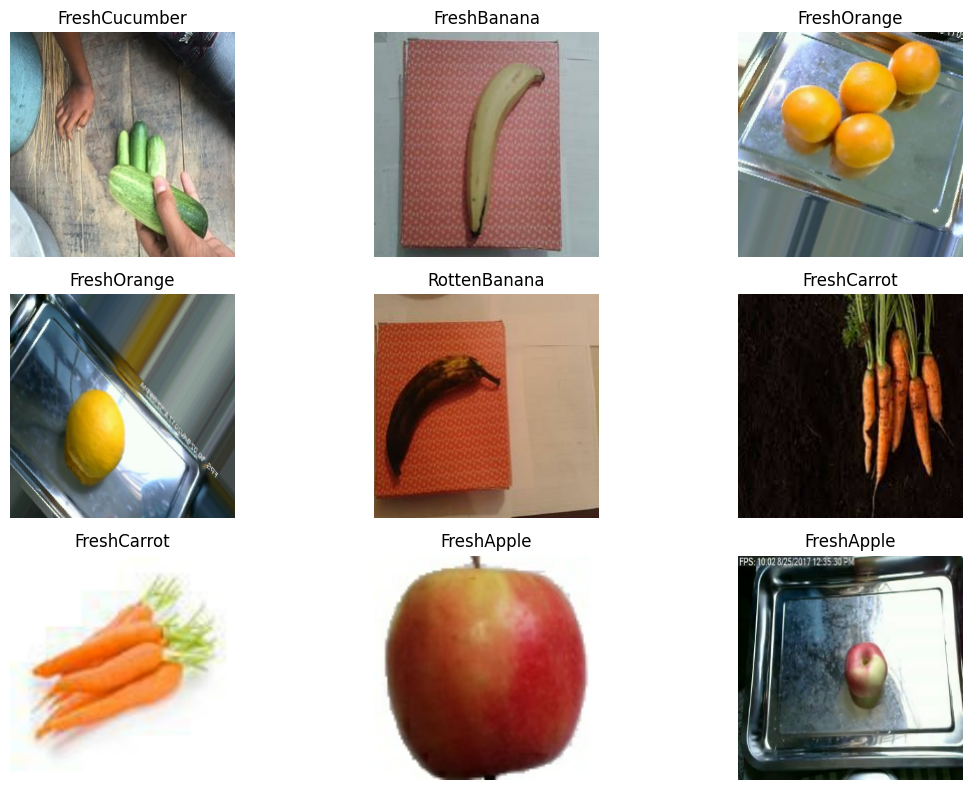

In [19]:

imagenes_lote, etiquetas_lote = next(iter(train_ds))

print("Forma del lote de imágenes:", imagenes_lote.shape)
print("Forma del lote de etiquetas:", etiquetas_lote.shape)
print("Tipo de dato:", imagenes_lote.dtype)
print("Valor mínimo:", float(tf.reduce_min(imagenes_lote)))
print("Valor máximo:", float(tf.reduce_max(imagenes_lote)))

plt.figure(figsize=(12, 8))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(
        tf.cast(imagenes_lote[i], tf.uint8).numpy()
    )
    indice = int(etiquetas_lote[i].numpy())
    plt.title(class_names[indice])
    plt.axis("off")

plt.tight_layout()
plt.show()


**Construir el modelo EfficientNetB0 con pesos ImageNet.**

In [20]:

base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = tf.keras.Model(inputs, outputs)

print("Modelo construido correctamente.")
print("Capas totales:", len(model.layers))
print("Parámetros totales:", model.count_params())
print("Parámetros entrenables:", sum(
    tf.keras.backend.count_params(w)
    for w in model.trainable_weights
))


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Modelo construido correctamente.
Capas totales: 5
Parámetros totales: 4075191
Parámetros entrenables: 25620


**Compilar el modelo.**

Utilizaremos Adam con una tasa de aprendizaje de 0.001 y entropía cruzada categórica dispersa, adecuada para nuestras etiquetas numéricas.

In [21]:

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 20)             │        25,620 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,075,191 (15.55 MB)

 Trainable params: 25,620 (100.08 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

**Configurar los callbacks de entrenamiento.**

In [22]:

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(CARPETA_TRABAJO / "mejor_modelo_inicial.keras"),
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Callbacks configurados correctamente.")


Callbacks configurados correctamente.


**Entrenar la primera fase de EfficientNetB0.**

En esta fase entrenaremos la capa clasificadora con la red base congelada durante un máximo de 15 épocas

In [23]:

history_inicial = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_INICIAL,
    callbacks=callbacks,
    verbose=1
)


Epoch 1/15
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 196ms/step - accuracy: 0.6469 - loss: 1.3670
Epoch 1: val_accuracy improved from None to 0.92351, saving model to /content/FruitVisionAI/mejor_modelo_inicial.keras

Epoch 1: finished saving model to /content/FruitVisionAI/mejor_modelo_inicial.keras
258/258 ━━━━━━━━━━━━━━━━━━━━ 144s 367ms/step - accuracy: 0.8027 - loss: 0.8080 - val_accuracy: 0.9235 - val_loss: 0.3165 - learning_rate: 0.0010
Epoch 2/15
257/258 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.9269 - loss: 0.3082
Epoch 2: val_accuracy improved from 0.92351 to 0.94561, saving model to /content/FruitVisionAI/mejor_modelo_inicial.keras

Epoch 2: finished saving model to /content/FruitVisionAI/mejor_modelo_inicial.keras
258/258 ━━━━━━━━━━━━━━━━━━━━ 25s 96ms/step - accuracy: 0.9301 - loss: 0.2864 - val_accuracy: 0.9456 - val_loss: 0.2127 - learning_rate: 0.0010
Epoch 3/15
256/258 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.9481 - loss: 0.2080
Epoch 3: val_accuracy improved from 0.9

**Sescongelar las últimas capas de EfficientNetB0.**

Se va realizar el fine-tuning, es decir, descongelar parcialmente EfficientNetB0 para adaptar sus características a nuestras 20 clases.

In [24]:

# Descongelar la red base
base_model.trainable = True

# Congelar todas las capas excepto las últimas 30
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Mantener BatchNormalization congeladas para mayor estabilidad
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

print("Total de capas:", len(base_model.layers))
print("Capas entrenables:", sum(
    layer.trainable for layer in base_model.layers
))
print("Parámetros entrenables:", sum(
    tf.keras.backend.count_params(w)
    for w in model.trainable_weights
))


Total de capas: 238
Capas entrenables: 23
Parámetros entrenables: 1508980


recompilar el modelo con una tasa de aprendizaje pequeña para ajustar las últimas capas sin alterar bruscamente los pesos preentrenados.

In [25]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modelo recompilado correctamente.")
print("Learning rate: 0.00001")
print("Parámetros entrenables:", sum(
    tf.keras.backend.count_params(w)
    for w in model.trainable_weights
))

Modelo recompilado correctamente.
Learning rate: 0.00001
Parámetros entrenables: 1508980


iniciar el fine-tuning: EfficientNetB0 ajustará sus últimas capas con una tasa de aprendizaje baja para especializarse en nuestras 20 categorías.

In [26]:
callbacks_fine = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(CARPETA_TRABAJO / "mejor_modelo_finetuning.keras"),
        monitor="val_accuracy",
        save_best_only=True,
        mode="max",
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-7,
        verbose=1
    )
]

print("Callbacks de fine-tuning configurados correctamente.")

Callbacks de fine-tuning configurados correctamente.


Se iniciara el entrenamiento de ajuste fino durante un máximo de 15 épocas.

In [27]:
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_FINE_TUNING,
    callbacks=callbacks_fine,
    verbose=1
)

Epoch 1/15
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 143ms/step - accuracy: 0.9859 - loss: 0.0550
Epoch 1: val_accuracy improved from None to 0.96657, saving model to /content/FruitVisionAI/mejor_modelo_finetuning.keras

Epoch 1: finished saving model to /content/FruitVisionAI/mejor_modelo_finetuning.keras
258/258 ━━━━━━━━━━━━━━━━━━━━ 83s 204ms/step - accuracy: 0.9857 - loss: 0.0537 - val_accuracy: 0.9666 - val_loss: 0.1023 - learning_rate: 1.0000e-05
Epoch 2/15
257/258 ━━━━━━━━━━━━━━━━━━━━ 0s 74ms/step - accuracy: 0.9862 - loss: 0.0468
Epoch 2: val_accuracy improved from 0.96657 to 0.96827, saving model to /content/FruitVisionAI/mejor_modelo_finetuning.keras

Epoch 2: finished saving model to /content/FruitVisionAI/mejor_modelo_finetuning.keras
258/258 ━━━━━━━━━━━━━━━━━━━━ 25s 96ms/step - accuracy: 0.9864 - loss: 0.0476 - val_accuracy: 0.9683 - val_loss: 0.0998 - learning_rate: 1.0000e-05
Epoch 3/15
258/258 ━━━━━━━━━━━━━━━━━━━━ 0s 75ms/step - accuracy: 0.9897 - loss: 0.0384
Epoch 3: val_accurac

**Cargar el mejor modelo**

In [28]:
modelo_final = tf.keras.models.load_model(
    CARPETA_TRABAJO / "mejor_modelo_finetuning.keras"
)

print("Modelo final cargado correctamente.")
print("Arquitectura:", modelo_final.name)
print("Número de clases:", modelo_final.output_shape[-1])
print("Parámetros totales:", modelo_final.count_params())

Modelo final cargado correctamente.
Arquitectura: functional
Número de clases: 20
Parámetros totales: 4075191


**Evaluación**

la evaluación con test_ds, nuestro conjunto de prueba independiente de 1.765 imágenes.

In [29]:
resultados_test = modelo_final.evaluate(
    test_ds,
    verbose=1,
    return_dict=True
)

print("\nRESULTADOS DE EVALUACIÓN")
for metrica, valor in resultados_test.items():
    print(f"{metrica}: {valor:.4f}")

56/56 ━━━━━━━━━━━━━━━━━━━━ 18s 177ms/step - accuracy: 0.9677 - loss: 0.0942

RESULTADOS DE EVALUACIÓN
accuracy: 0.9677
loss: 0.0942


**Métricas por categoría**

In [30]:
# Generar predicciones sobre el conjunto de prueba
predicciones_prob = modelo_final.predict(test_ds, verbose=1)

y_pred = np.argmax(predicciones_prob, axis=1)

# Obtener las etiquetas reales
y_true = np.concatenate([
    etiquetas.numpy() for _, etiquetas in test_ds
])

# Informe de clasificación
informe = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
    zero_division=0
)

print("INFORME DE CLASIFICACIÓN POR CATEGORÍA")
print(informe)

56/56 ━━━━━━━━━━━━━━━━━━━━ 21s 191ms/step
INFORME DE CLASIFICACIÓN POR CATEGORÍA
                  precision    recall  f1-score   support

      FreshApple     0.9681    1.0000    0.9838        91
     FreshBanana     0.9894    1.0000    0.9947        93
 FreshBellpepper     0.9468    0.9889    0.9674        90
     FreshCarrot     0.9770    0.9341    0.9551        91
   FreshCucumber     0.9780    1.0000    0.9889        89
      FreshMango     0.9889    0.9889    0.9889        90
     FreshOrange     1.0000    1.0000    1.0000        92
     FreshPotato     0.9778    0.9565    0.9670        92
 FreshStrawberry     1.0000    1.0000    1.0000        90
     FreshTomato     1.0000    1.0000    1.0000        91
     RottenApple     0.9302    0.9091    0.9195        88
    RottenBanana     0.9886    1.0000    0.9943        87
RottenBellpepper     0.9103    0.8659    0.8875        82
    RottenCarrot     0.8846    0.9079    0.8961        76
  RottenCucumber     0.9651    0.9651    0.9651 

**Matriz de confusión**

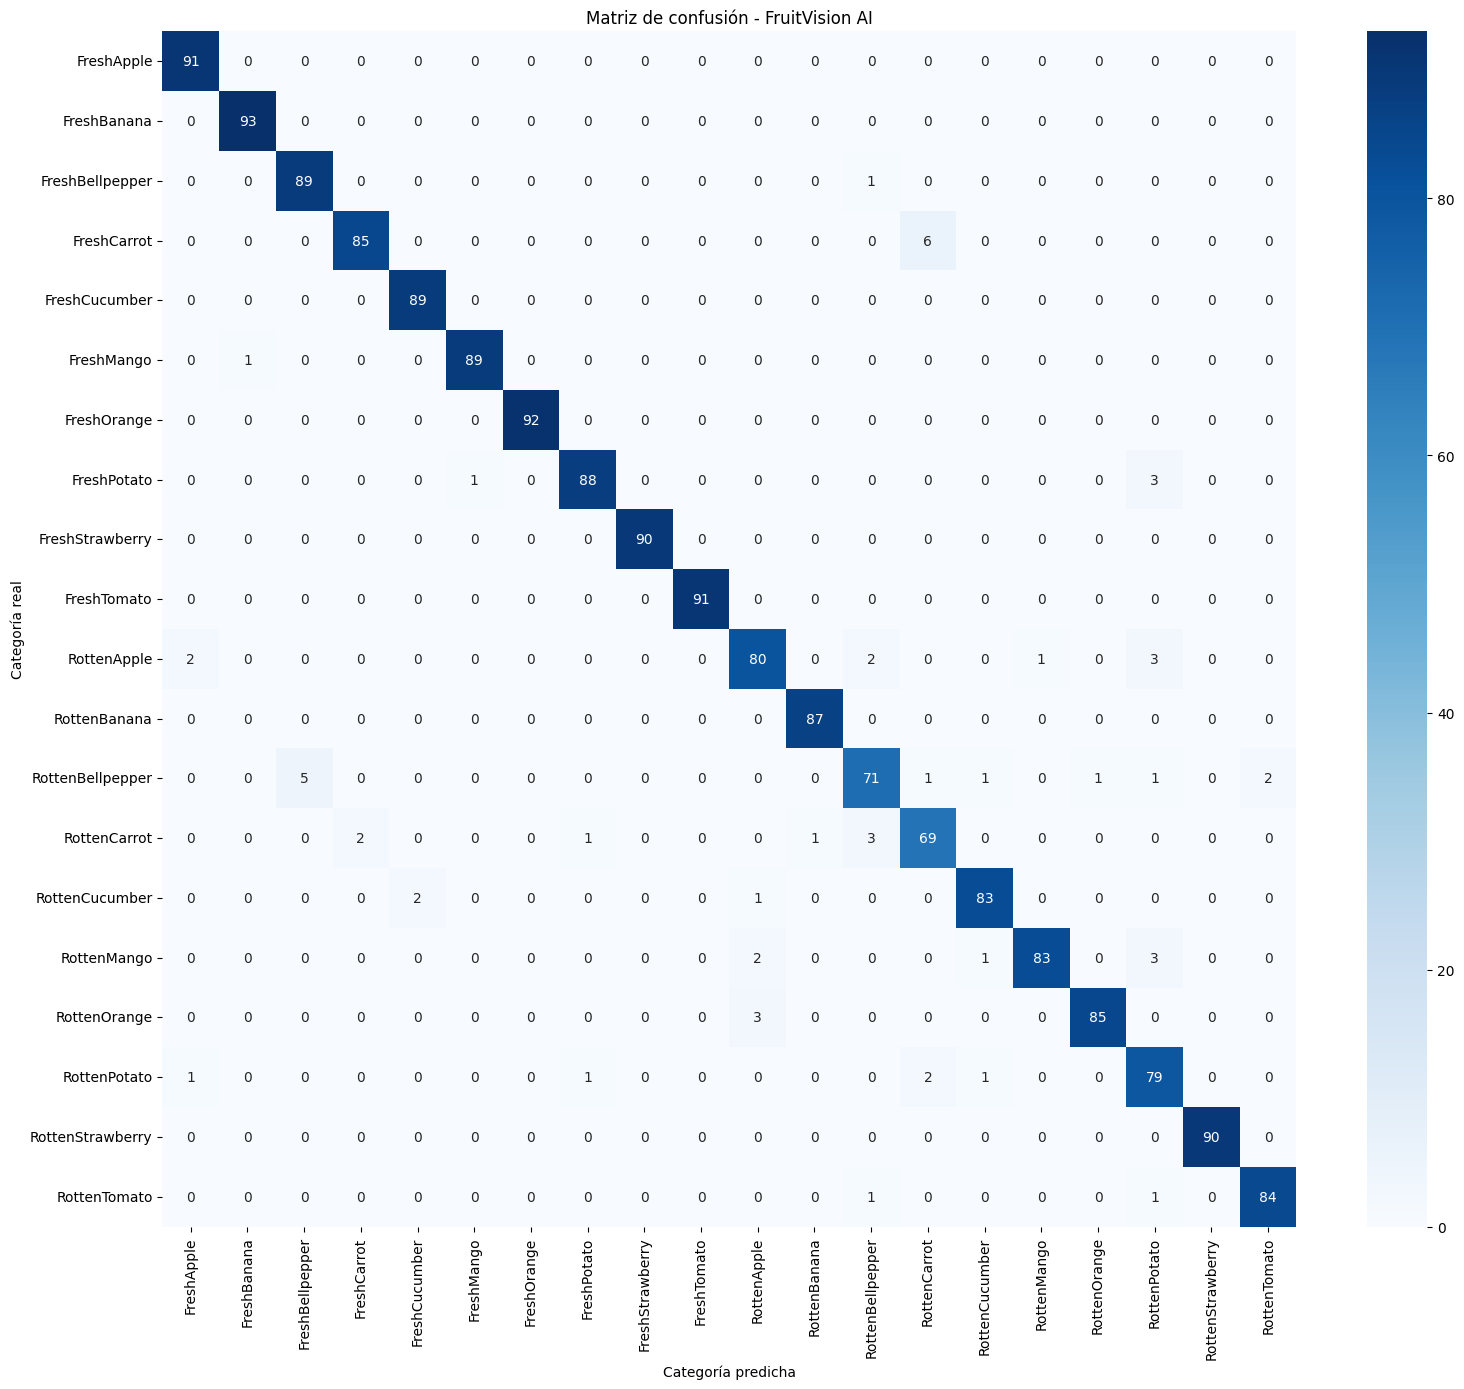

In [31]:
# Calcular matriz de confusión
matriz_confusion = confusion_matrix(
    y_true,
    y_pred,
    labels=range(NUM_CLASSES)
)

# Visualizar resultados
plt.figure(figsize=(16, 14))

sns.heatmap(
    matriz_confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Matriz de confusión - FruitVision AI")
plt.xlabel("Categoría predicha")
plt.ylabel("Categoría real")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

**Identificar automáticamente las confusiones**

In [32]:
# Extraer errores de la matriz de confusión
errores = []

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        if i != j and matriz_confusion[i, j] > 0:
            errores.append({
                "Categoria_real": class_names[i],
                "Categoria_predicha": class_names[j],
                "Cantidad": int(matriz_confusion[i, j])
            })

df_errores = pd.DataFrame(errores)
df_errores = df_errores.sort_values(
    by="Cantidad",
    ascending=False
).reset_index(drop=True)

print("PRINCIPALES CONFUSIONES DEL MODELO")
display(df_errores.head(15))

print("\nTotal de predicciones incorrectas:", len(y_true) - np.sum(y_true == y_pred))

PRINCIPALES CONFUSIONES DEL MODELO


,Categoria_real,Categoria_predicha,Cantidad
0,FreshCarrot,RottenCarrot,6
1,RottenBellpepper,FreshBellpepper,5
2,FreshPotato,RottenPotato,3
3,RottenApple,RottenPotato,3
4,RottenOrange,RottenApple,3
5,RottenMango,RottenPotato,3
6,RottenCarrot,RottenBellpepper,3
7,RottenCarrot,FreshCarrot,2
8,RottenCucumber,FreshCucumber,2
9,RottenPotato,RottenCarrot,2



Total de predicciones incorrectas: 57


**Guardar los resultados de evaluación**

In [33]:
# Generar métricas completas
reporte_dict = classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

metricas_finales = {
    "modelo": "EfficientNetB0",
    "numero_clases": NUM_CLASSES,
    "imagenes_prueba": len(y_true),
    "accuracy": float(accuracy_score(y_true, y_pred)),
    "loss": float(resultados_test["loss"]),
    "precision_macro": reporte_dict["macro avg"]["precision"],
    "recall_macro": reporte_dict["macro avg"]["recall"],
    "f1_macro": reporte_dict["macro avg"]["f1-score"],
    "precision_weighted": reporte_dict["weighted avg"]["precision"],
    "recall_weighted": reporte_dict["weighted avg"]["recall"],
    "f1_weighted": reporte_dict["weighted avg"]["f1-score"],
    "predicciones_incorrectas": int(len(y_true) - np.sum(y_true == y_pred))
}

# Guardar métricas en JSON
with open(CARPETA_TRABAJO / "metrics.json", "w", encoding="utf-8") as archivo:
    json.dump(metricas_finales, archivo, indent=4, ensure_ascii=False)

# Guardar informe por categoría
pd.DataFrame(reporte_dict).transpose().to_csv(
    CARPETA_TRABAJO / "classification_report.csv",
    encoding="utf-8"
)

# Guardar matriz de confusión
pd.DataFrame(
    matriz_confusion,
    index=class_names,
    columns=class_names
).to_csv(CARPETA_TRABAJO / "confusion_matrix.csv", encoding="utf-8")

# Guardar errores
df_errores.to_csv(
    CARPETA_TRABAJO / "errores_confusion.csv",
    index=False,
    encoding="utf-8"
)

print("Resultados guardados correctamente:")
for nombre in [
    "metrics.json",
    "classification_report.csv",
    "confusion_matrix.csv",
    "errores_confusion.csv"
]:
    print("-", nombre)

print("\nMÉTRICAS FINALES")
print(json.dumps(metricas_finales, indent=4, ensure_ascii=False))

Resultados guardados correctamente:
- metrics.json
- classification_report.csv
- confusion_matrix.csv
- errores_confusion.csv

MÉTRICAS FINALES
{
    "modelo": "EfficientNetB0",
    "numero_clases": 20,
    "imagenes_prueba": 1765,
    "accuracy": 0.9677053824362606,
    "loss": 0.09420555830001831,
    "precision_macro": 0.9667900874375348,
    "recall_macro": 0.9666017385804114,
    "f1_macro": 0.9664789884022198,
    "precision_weighted": 0.9680571579869615,
    "recall_weighted": 0.9677053824362606,
    "f1_weighted": 0.9676676957057264,
    "predicciones_incorrectas": 57
}


**Guardar el modelo final .keras**

In [34]:
# Guardar el modelo final de FruitVision AI
ruta_modelo_final = CARPETA_TRABAJO / "fruitvision_ai_model.keras"

modelo_final.save(ruta_modelo_final)

# Verificar que el archivo existe
if ruta_modelo_final.exists():
    tamanio_mb = ruta_modelo_final.stat().st_size / (1024 * 1024)

    print("Modelo exportado correctamente.")
    print("Archivo:", ruta_modelo_final.name)
    print(f"Tamaño: {tamanio_mb:.2f} MB")
else:
    print("ERROR: No se pudo verificar el archivo del modelo.")

Modelo exportado correctamente.
Archivo: fruitvision_ai_model.keras
Tamaño: 27.87 MB


**Verificar el modelo exportado**

In [35]:
# Cargar el modelo desde el archivo exportado
modelo_verificacion = tf.keras.models.load_model(
    CARPETA_TRABAJO / "fruitvision_ai_model.keras"
)

# Obtener un lote real del conjunto de prueba
imagenes_lote, etiquetas_lote = next(iter(test_ds))

# Realizar predicciones
predicciones = modelo_verificacion.predict(
    imagenes_lote[:5],
    verbose=0
)

print("VERIFICACIÓN DEL MODELO EXPORTADO")
print("Modelo cargado correctamente.")
print("Forma de salida:", predicciones.shape)

for i in range(5):
    indice_predicho = np.argmax(predicciones[i])
    indice_real = int(etiquetas_lote[i].numpy())
    confianza = float(np.max(predicciones[i])) * 100

    print(f"\nImagen {i + 1}")
    print("Categoría real:", class_names[indice_real])
    print("Categoría predicha:", class_names[indice_predicho])
    print(f"Confianza: {confianza:.2f}%")

VERIFICACIÓN DEL MODELO EXPORTADO
Modelo cargado correctamente.
Forma de salida: (5, 20)

Imagen 1
Categoría real: RottenCarrot
Categoría predicha: RottenCarrot
Confianza: 97.56%

Imagen 2
Categoría real: RottenCucumber
Categoría predicha: RottenCucumber
Confianza: 55.34%

Imagen 3
Categoría real: RottenBanana
Categoría predicha: RottenBanana
Confianza: 100.00%

Imagen 4
Categoría real: RottenPotato
Categoría predicha: RottenPotato
Confianza: 99.24%

Imagen 5
Categoría real: FreshCucumber
Categoría predicha: FreshCucumber
Confianza: 100.00%


**Guardar el historial de entrenamiento**

In [36]:
# Unir los historiales de las dos fases
historial_inicial_df = pd.DataFrame(history_inicial.history)
historial_inicial_df["fase"] = "entrenamiento_inicial"
historial_inicial_df["epoca"] = range(1, len(historial_inicial_df) + 1)

historial_fine_df = pd.DataFrame(history_fine.history)
historial_fine_df["fase"] = "fine_tuning"
historial_fine_df["epoca"] = range(1, len(historial_fine_df) + 1)

# Combinar ambos historiales
historial_completo = pd.concat(
    [historial_inicial_df, historial_fine_df],
    ignore_index=True
)

# Guardar CSV
ruta_historial = CARPETA_TRABAJO / "training_history.csv"
historial_completo.to_csv(ruta_historial, index=False)

print("Historial de entrenamiento guardado.")
print("Archivo:", ruta_historial.name)
print("Total de épocas registradas:", len(historial_completo))
display(historial_completo.tail())

Historial de entrenamiento guardado.
Archivo: training_history.csv
Total de épocas registradas: 29


,accuracy,loss,val_accuracy,val_loss,learning_rate,fase,epoca
24,0.992108,0.029512,0.971105,0.098098,2.000000e-06,fine_tuning,10
25,0.992108,0.029860,0.971105,0.098244,2.000000e-06,fine_tuning,11
26,0.992108,0.028109,0.971105,0.098347,4.000000e-07,fine_tuning,12
27,0.992593,0.028231,0.971105,0.098552,4.000000e-07,fine_tuning,13
28,0.991744,0.028300,0.971105,0.098512,1.000000e-07,fine_tuning,14


**Visualizar las curvas de entrenamiento**

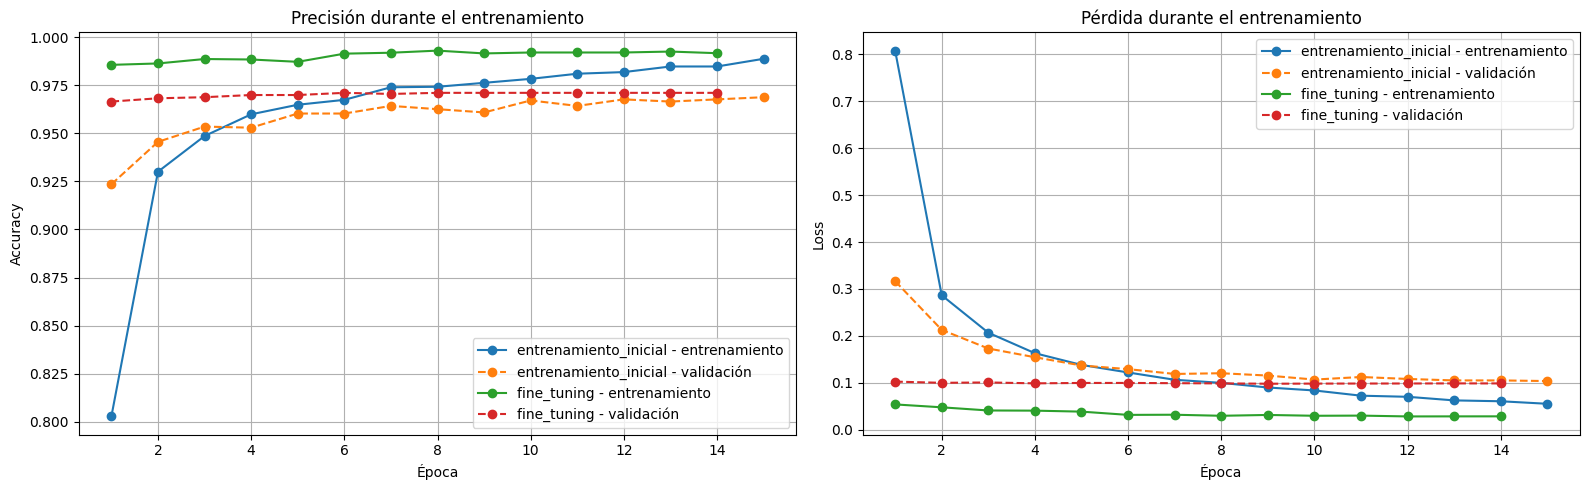

Gráficas guardadas en: /content/FruitVisionAI/curvas_entrenamiento.png


In [37]:
# Crear figura con dos gráficas
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Curva de precisión
for fase, datos in historial_completo.groupby("fase"):
    axes[0].plot(datos["epoca"], datos["accuracy"], marker="o", label=f"{fase} - entrenamiento")
    axes[0].plot(datos["epoca"], datos["val_accuracy"], marker="o", linestyle="--", label=f"{fase} - validación")

axes[0].set_title("Precisión durante el entrenamiento")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Curva de pérdida
for fase, datos in historial_completo.groupby("fase"):
    axes[1].plot(datos["epoca"], datos["loss"], marker="o", label=f"{fase} - entrenamiento")
    axes[1].plot(datos["epoca"], datos["val_loss"], marker="o", linestyle="--", label=f"{fase} - validación")

axes[1].set_title("Pérdida durante el entrenamiento")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()

# Guardar gráficas
ruta_graficas = CARPETA_TRABAJO / "curvas_entrenamiento.png"
plt.savefig(ruta_graficas, dpi=300, bbox_inches="tight")
plt.show()

print("Gráficas guardadas en:", ruta_graficas)

Interpretación de las gráficas
1. Precisión: el entrenamiento inicial llegó aproximadamente al 98,9 % de accuracy. Con fine-tuning alcanzó alrededor del 99,3 %.
2. Validación: la precisión mejoró hasta el 97,11 %, sin fluctuaciones importantes.
3. Pérdida: disminuyó progresivamente durante el entrenamiento inicial y se mantuvo estable durante el fine-tuning.
4. Sobreajuste: existe una diferencia entre entrenamiento y validación, pero no parece excesiva. La evaluación independiente de 96,77 % respalda la capacidad de generalización.

**Verificar los archivos del proyecto**

In [38]:
# Revisar los archivos generados durante el proyecto
print("ARCHIVOS DE FRUITVISION AI\n")

for archivo in sorted(CARPETA_TRABAJO.iterdir()):
    if archivo.is_file():
        tamanio_mb = archivo.stat().st_size / (1024 * 1024)
        print(f"{archivo.name:40} {tamanio_mb:.2f} MB")

print("\nTotal de archivos:", sum(
    1 for archivo in CARPETA_TRABAJO.iterdir()
    if archivo.is_file()
))

ARCHIVOS DE FRUITVISION AI

class_names.json                         0.00 MB
classification_report.csv                0.00 MB
conflictos_excluidos.csv                 0.00 MB
confusion_matrix.csv                     0.00 MB
curvas_entrenamiento.png                 0.35 MB
errores_confusion.csv                    0.00 MB
fruitvision_ai_model.keras               27.87 MB
manifest_clean.csv                       2.90 MB
mejor_modelo_finetuning.keras            27.87 MB
mejor_modelo_inicial.keras               16.55 MB
metrics.json                             0.00 MB
test.csv                                 0.43 MB
train.csv                                2.03 MB
training_history.csv                     0.00 MB
validation.csv                           0.43 MB

Total de archivos: 15


**Empaquetar el proyecto**

In [39]:
import shutil
from pathlib import Path

ruta_zip = shutil.make_archive(
    "/content/FruitVisionAI_entrenamiento_completo",
    "zip",
    root_dir="/content",
    base_dir="FruitVisionAI"
)

archivo_zip = Path(ruta_zip)

print("EMPAQUETADO COMPLETADO")
print("Archivo:", archivo_zip.name)
print(f"Tamaño: {archivo_zip.stat().st_size / (1024 * 1024):.2f} MB")
print("Ruta:", archivo_zip)

EMPAQUETADO COMPLETADO
Archivo: FruitVisionAI_entrenamiento_completo.zip
Tamaño: 66.20 MB
Ruta: /content/FruitVisionAI_entrenamiento_completo.zip


**Descragar archivos**

In [40]:
from google.colab import files

files.download(
    "/content/FruitVisionAI_entrenamiento_completo.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>